In [1]:
import os
import sys
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

project_root = "/Users/elie/Documents/GitHub/quant_data/"
kf_dir = os.path.join(project_root, "personal", "Kalman_filter_spline")
sanos_kf_dir = os.path.join(project_root, "personal", "SANOS_KF_Strike")
for p in [project_root, kf_dir, sanos_kf_dir]:
    if p not in sys.path:
        sys.path.insert(0, p)

os.environ.setdefault("QUANTDATA_RAW_DATA", "/quantdata/raw")

from fitter_regularized import FitterRegularized

from personal.Kalman_filter_spline.SANOS.sanos_option import (
    _iv_from_norm_call,
    _iv_from_norm_put,
    _v_atm_from_price,
)
from personal.Kalman_filter_spline.surface_kalman_filters import build_iv_observations
from quantdata.biz_calendar import NMS
from quantdata.massive.client import MassiveClient
from quantdata.sanos.fitter import Fitter
from quantdata.sanos.grid import GridGeometry, GridSanos

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [2]:
TICKER = "SPY"
TRADE_DATE = date(2024, 1, 3)
BATCH_FREQ = "1m"  # "1s" | "1m" | "5m"
MIN_TRADES = 100
N_VIZ = 6

# Geometry boundaries (fraction of the lowest / highest observed anchor)
LOWER_SCALE = 0.9  # lower boundary = LOWER_SCALE * min anchor
UPPER_SCALE = 1.1  # upper boundary = UPPER_SCALE * max anchor
DLV_MIN = 0.001
DLV_MAX = 2.0  # large: short-dated options need DLV ~ strike_range/T ~ 10+
CALLS_ONLY = True  # skip puts entirely; no PCP conversion
PUTS_ONLY = False  # skip calls entirely; only use puts
REGULARIZER_WEIGHT = 1e-6  # second-difference (log_dlv_space=False) or log-barrier (True) weight
LOG_DLV_SPACE = True  # True → log-barrier regularizer  −λ·Σlog(dᵢ);  False → legacy second-diff
TEMPORAL_REGULARIZER_WEIGHT = 1.0  # λ_T · Σᵢ((dᵢ−d̂ᵢ)/d̂ᵢ)²; 0.0 = off
TEMPORAL_WEIGHT_CLIP = 100.0  # caps weight ratio at C; floor = mean(d̂)/C; raise to allow more extremes, inf for no clipping

BID_ASK_PENALTY_WEIGHT = (
    0.0  # 1e10  # quadratic penalty for prices outside bid-ask (0 = off, try 1e4–1e6)
)

In [3]:
df_tickers = pl.read_csv(os.path.join(project_root, "personal", "spy_options_tickers.csv"))

client = MassiveClient()
df_spy = client.fetch_trades(TICKER, TRADE_DATE)

df_quotes_all, df_trades_all = build_iv_observations(
    df_tickers, TRADE_DATE, df_spy, min_trades=MIN_TRADES
)

print(f"quotes: {len(df_quotes_all):,}   trades: {len(df_trades_all):,}")
print("columns:", df_quotes_all.columns)
df_quotes_all.head(3)

Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105P00462500: 17 bad quotes
Expiry 2024-01-05: implied forward from 13 strike(s)
quotes: 2,115,510   trades: 74,099
columns: ['ts_ns', 'strike', 'is_call', 'log_moneyness', 'T', 'observed_iv', 'bid_iv', 'ask_iv', 'R_iv', 'bid_price', 'ask_price', 'forward', 'discount_factor']


ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,discount_factor
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.13695,0.134075,0.139497,0.000007,0.09,0.11,470.43,null
2024-01-03 09:30:00.008294144 EST,471.0,false,0.001211,0.006217,0.127732,0.126371,0.129092,0.000002,2.17,2.21,470.43,null
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43,null


In [4]:
df_quotes_all = df_quotes_all.drop_nulls()

In [5]:
df_quotes_all["discount_factor"]

discount_factor
f64
1.002
1.002
1.002
1.002
1.002
…
1.0
1.0
1.0


In [6]:
# Normalize prices by F * df  (discount_factor defaults to 1 if null or absent)
has_df = "discount_factor" in df_quotes_all.columns
df_scale = pl.col("forward") * pl.col("discount_factor") if has_df else pl.col("forward")

df_q = df_quotes_all.with_columns(
    (pl.col("bid_price") / df_scale).alias("bid_norm"),
    (pl.col("ask_price") / df_scale).alias("ask_norm"),
    ((pl.col("bid_price") + pl.col("ask_price")) / 2.0 / df_scale).alias("mid_norm"),
    pl.col("log_moneyness").exp().alias("pure_strike"),
)

df_calls = df_q.filter(pl.col("is_call"))
df_puts = df_q.filter(~pl.col("is_call"))

tte_y_max = float(df_q["T"].max())
tte_y_med = float(df_q["T"].median())
print(f"calls: {len(df_calls):,}   puts: {len(df_puts):,}")
print(f"T range: [{df_q['T'].min():.5f}, {tte_y_max:.5f}]  median={tte_y_med:.5f}")
print(f"bid_norm null count: {df_q['bid_norm'].null_count()}")

calls: 956,381   puts: 1,159,090
T range: [0.00545, 0.00622]  median=0.00582
bid_norm null count: 0


In [7]:
# Build single-expiry GridGeometry anchored at the observed call strikes.
#
# Key constraint in SANOS: dlvbox[0] = dlvbox[-1] = 0, which forces C_T = C_0
# (intrinsic at density0, a point mass at ref_fwd) at the FIRST and LAST
# interior anchor positions.  If those positions are observation strikes, the
# model price there is rigidly pinned to the intrinsic at ref_fwd — but market
# prices are normalised by the per-snapshot forward F_snap ≠ ref_fwd, causing
# systematic bid-ask violations proportional to the intraday forward drift.
#
# Fix: one unobserved padding anchor on each side absorbs the dlvbox=0 pin.
# Every observation anchor then has full DLV freedom.

tte_geom = tte_y_max * 1.1
t_vals = np.array([0.0, tte_geom])

# Use put strikes for geometry when PUTS_ONLY so the anchor grid spans the
# right range; put and call strikes are the same for SPY but differ in general.
df_anchor = df_puts if PUTS_ONLY else df_calls
ref_fwd = float(df_anchor["forward"].median())

abs_strikes = np.sort(df_anchor["strike"].unique().to_numpy().astype(float))
obs_ks = abs_strikes / ref_fwd

lo = obs_ks[0] * LOWER_SCALE
hi = obs_ks[-1] * UPPER_SCALE

N_PAD = 1
lo_pads = np.linspace(lo, obs_ks[0], N_PAD + 2)[1:-1]  # strictly between lo and obs_ks[0]
hi_pads = np.linspace(obs_ks[-1], hi, N_PAD + 2)[1:-1]  # strictly between obs_ks[-1] and hi

xstrikes_row = np.concatenate([[lo], lo_pads, obs_ks, hi_pads, [hi]])
xstrikes = np.tile(xstrikes_row, (2, 1))

assert xstrikes[1, 1] < 1.0, "first pad must be below ATM"
assert xstrikes[1, -2] > 1.0, "last pad must be above ATM"

geom = GridGeometry(xexpiries=t_vals, xstrikes=xstrikes, dlv_min=DLV_MIN, dlv_max=DLV_MAX)
grid_sanos = GridSanos(geometry=geom)
fitter = FitterRegularized(
    geometry=geom,
    no_warnings=True,
    max_error=None,
    regularizer_weight=REGULARIZER_WEIGHT,
    log_dlv_space=LOG_DLV_SPACE,
    temporal_regularizer_weight=TEMPORAL_REGULARIZER_WEIGHT,
    temporal_weight_clip=TEMPORAL_WEIGHT_CLIP,
    bid_ask_penalty_weight=BID_ASK_PENALTY_WEIGHT,
)

anchor_pure = xstrikes[1, 1:-1]  # (N,) all interior anchors incl. pads
anchor_lk = np.log(anchor_pure)
interior_pure = xstrikes[1, 2:-2]  # (N-2,) non-boundary anchors; aligns with dlvsqs
interior_lk = np.log(interior_pure)

print(f"Geometry: T={geom.T}, N={geom.N}")
print(f"  ref_fwd: {ref_fwd:.4f}")
print(
    f"  {len(abs_strikes)} observed strikes + {2 * N_PAD} pads → {geom.N} interior anchors + 2 boundaries"
)
print(f"  anchor range:   [{anchor_pure[0]:.4f}, {anchor_pure[-1]:.4f}]")
print(f"  interior range: [{interior_pure[0]:.4f}, {interior_pure[-1]:.4f}]")
print(f"  dlvbox=0 pins at: {anchor_pure[0]:.4f} (lo_pad) and {anchor_pure[-1]:.4f} (hi_pad)")
print(f"  regularizer_weight: {REGULARIZER_WEIGHT}  log_dlv_space: {LOG_DLV_SPACE}")
print(
    f"  temporal_regularizer_weight: {TEMPORAL_REGULARIZER_WEIGHT}  temporal_weight_clip: {TEMPORAL_WEIGHT_CLIP}"
)
print(f"  bid_ask_penalty_weight: {BID_ASK_PENALTY_WEIGHT}")

Geometry: T=1, N=19
  ref_fwd: 470.0629
  17 observed strikes + 2 pads → 19 interior anchors + 2 boundaries
  anchor range:   [0.9175, 1.0722]
  interior range: [0.9658, 1.0211]
  dlvbox=0 pins at: 0.9175 (lo_pad) and 1.0722 (hi_pad)
  regularizer_weight: 1e-06  log_dlv_space: True
  temporal_regularizer_weight: 1.0  temporal_weight_clip: 100.0
  bid_ask_penalty_weight: 0.0


In [8]:
def make_batch_snapshots(df: pl.DataFrame, batch_freq: str) -> pl.DataFrame:
    if batch_freq == "tick":
        df = df.with_columns(pl.col("ts_ns").alias("batch_ts"))
    elif batch_freq in ("1s", "1m", "5m"):
        df = df.with_columns(pl.col("ts_ns").dt.truncate(batch_freq).alias("batch_ts"))
    else:
        raise ValueError(f"Unknown BATCH_FREQ: {batch_freq!r}")

    return (
        df.sort("ts_ns")
        .group_by(["batch_ts", "strike"])
        .agg(
            [
                pl.col("log_moneyness").last(),
                pl.col("pure_strike").last(),
                pl.col("bid_norm").last(),
                pl.col("ask_norm").last(),
                pl.col("mid_norm").last(),
                pl.col("T").last(),
                pl.col("forward").last(),
            ]
        )
        .sort(["batch_ts", "strike"])
    )


snaps_calls = make_batch_snapshots(df_calls, BATCH_FREQ)
snaps_puts = make_batch_snapshots(df_puts, BATCH_FREQ)

batch_ts_list = sorted(snaps_calls["batch_ts"].unique().to_list())
print(f"{len(batch_ts_list)} snapshots at {BATCH_FREQ} frequency")
print(f"first: {batch_ts_list[0]}   last: {batch_ts_list[-1]}")

405 snapshots at 1m frequency
first: 2024-01-03 09:30:00-05:00   last: 2024-01-03 16:14:00-05:00


In [9]:
try:
    from tqdm.auto import tqdm
except ImportError:

    def tqdm(x, **kw):
        return x


results = []
n_failed = 0
_err_shown = False
prev_densities = (
    None  # last successfully solved density; fed as temporal reference to next snapshot
)

for batch_ts in tqdm(batch_ts_list, desc="Fitting snapshots"):
    snap_c = snaps_calls.filter(pl.col("batch_ts") == batch_ts).sort("pure_strike")
    snap_p = snaps_puts.filter(pl.col("batch_ts") == batch_ts).sort("pure_strike")

    T_snap = (
        float(snap_c["T"].median())
        if not snap_c.is_empty()
        else (float(snap_p["T"].median()) if not snap_p.is_empty() else tte_y_med)
    )
    fwd_snap = (
        float(snap_p["forward"].median())
        if PUTS_ONLY and not snap_p.is_empty()
        else float(snap_c["forward"].median())
        if not snap_c.is_empty()
        else float("nan")
    )

    # ATM IV via scalar BS inversion at nearest-ATM option
    atm_iv = 0.20
    snap_atm = snap_p if PUTS_ONLY else snap_c
    if not snap_atm.is_empty():
        lk_atm = np.log(snap_atm["pure_strike"].to_numpy().astype(float))
        atm_idx = int(np.argmin(np.abs(lk_atm)))
        V_atm = _v_atm_from_price(
            float(snap_atm["mid_norm"][atm_idx]),
            float(lk_atm[atm_idx]),
            T_snap,
            is_call=not PUTS_ONLY,
        )
        if np.isfinite(V_atm) and V_atm > 0:
            atm_iv = float(np.sqrt(V_atm / max(T_snap, 1e-8)))

    # ── Assemble observations ────────────────────────────────────────────
    dlvsqs = densities = None
    failed = True
    parts = []
    if not snap_c.is_empty() and not PUTS_ONLY:
        parts.append(snap_c.with_columns(pl.lit(True).alias("is_call")))
    if not snap_p.is_empty() and not CALLS_ONLY:
        parts.append(snap_p.with_columns(pl.lit(False).alias("is_call")))

    K_lo_obs = float("nan")
    K_hi_obs = float("nan")
    if parts:
        snap_obs = pl.concat(parts).sort("pure_strike")
        pure_K = snap_obs["pure_strike"].to_numpy().astype(float)
        if len(pure_K) > 0:
            K_lo_obs = float(np.min(pure_K))
            K_hi_obs = float(np.max(pure_K))
        bid_n = snap_obs["bid_norm"].to_numpy().astype(float)
        ask_n = snap_obs["ask_norm"].to_numpy().astype(float)
        tte_arr = np.full(len(pure_K), T_snap)
        is_calls = snap_obs["is_call"].to_numpy().astype(bool)
        try:
            dlvsqs, _, densities = fitter.fit_prepared(
                fwd_vols=None,
                opt_strikes=pure_K,
                opt_bid=bid_n,
                opt_ask=ask_n,
                opt_tte=tte_arr,
                opt_is_calls=is_calls,
                return_only_dlvsqs=False,
                prev_densities=prev_densities,
            )
            failed = False
            prev_densities = densities  # update reference for next snapshot
        except Exception as exc:
            n_failed += 1
            if not _err_shown:
                print(f"[fit] first error at {batch_ts}: {type(exc).__name__}: {exc}")
                _err_shown = True

    results.append(
        dict(
            ts=batch_ts,
            T=T_snap,
            fwd=fwd_snap,
            atm_iv=atm_iv,
            dlvsqs=dlvsqs,
            densities=densities,
            n_calls=len(snap_c),
            n_puts=len(snap_p),
            K_lo_obs=K_lo_obs,
            K_hi_obs=K_hi_obs,
            failed=failed,
        )
    )

good = [r for r in results if not r["failed"]]
print(f"Done.  Failed: {n_failed}/{len(results)}")

[fit] first error at 2024-01-03 10:39:00-05:00: SolverError: Solver 'CLARABEL' failed. Try another solver, or solve with verbose=True for more information.
Done.  Failed: 5/405


In [10]:
# ── Observed-range diagnostics — unconstrained zone width ─────────────────
# K_lo_obs: lowest observed strike (K/F_ref). For calls the extrapolated zone is below it.
# K_hi_obs: highest observed strike (K/F_ref). For puts the extrapolated zone is above it.

import pandas as pd

rows = []
for r in results:
    if r["failed"] or r["densities"] is None:
        continue
    k_lo = r.get("K_lo_obs", float("nan"))
    k_hi = r.get("K_hi_obs", float("nan"))
    d = r["densities"][0] if isinstance(r["densities"], np.ndarray) else r["densities"][0]
    mart = float(np.abs(anchor_pure @ d - 1.0))
    rows.append(
        dict(
            ts=r["ts"],
            K_lo_obs=k_lo,
            K_hi_obs=k_hi,
            martingale_residual=mart,
        )
    )

df_diag = pd.DataFrame(rows)
print(df_diag[["ts", "K_lo_obs", "K_hi_obs", "martingale_residual"]].to_string())
print(f"\nmean K_lo_obs:            {df_diag['K_lo_obs'].mean():.4f}")
print(f"mean K_hi_obs:            {df_diag['K_hi_obs'].mean():.4f}")
print(f"max martingale residual:  {df_diag['martingale_residual'].max():.2e}")

# Show which interior anchors fall in the extrapolated zone
if PUTS_ONLY:
    median_k_bound = float(df_diag["K_hi_obs"].median())
    extrap_mask = interior_pure >= median_k_bound
    extrap_label = f"K/F ≥ {median_k_bound:.4f}"
else:
    median_k_bound = float(df_diag["K_lo_obs"].median())
    extrap_mask = interior_pure <= median_k_bound
    extrap_label = f"K/F ≤ {median_k_bound:.4f}"

print(
    f"\nExtrapolated interior anchors ({extrap_label}): {extrap_mask.sum()} of {len(interior_pure)}"
)
print(f"  K/F values: {np.round(interior_pure[extrap_mask], 4)}")

                           ts  K_lo_obs  K_hi_obs  martingale_residual
0   2024-01-03 09:30:00-05:00  0.964248  1.019469         2.329590e-08
1   2024-01-03 09:31:00-05:00  0.964357  1.019552         0.000000e+00
2   2024-01-03 09:32:00-05:00  0.964769  1.020040         4.440892e-16
3   2024-01-03 09:33:00-05:00  0.965056  1.020248         2.220446e-16
4   2024-01-03 09:34:00-05:00  0.964900  1.020148         3.330669e-16
5   2024-01-03 09:35:00-05:00  0.964657  1.019866         0.000000e+00
6   2024-01-03 09:36:00-05:00  0.964939  1.020215         5.551115e-16
7   2024-01-03 09:37:00-05:00  0.964890  1.020226         0.000000e+00
8   2024-01-03 09:38:00-05:00  0.964746  1.020015         0.000000e+00
9   2024-01-03 09:39:00-05:00  0.964892  1.020118         2.220446e-16
10  2024-01-03 09:40:00-05:00  0.964779  1.020026         2.220446e-16
11  2024-01-03 09:41:00-05:00  0.964299  1.019545         0.000000e+00
12  2024-01-03 09:42:00-05:00  0.964585  1.019801         2.220446e-16
13  20

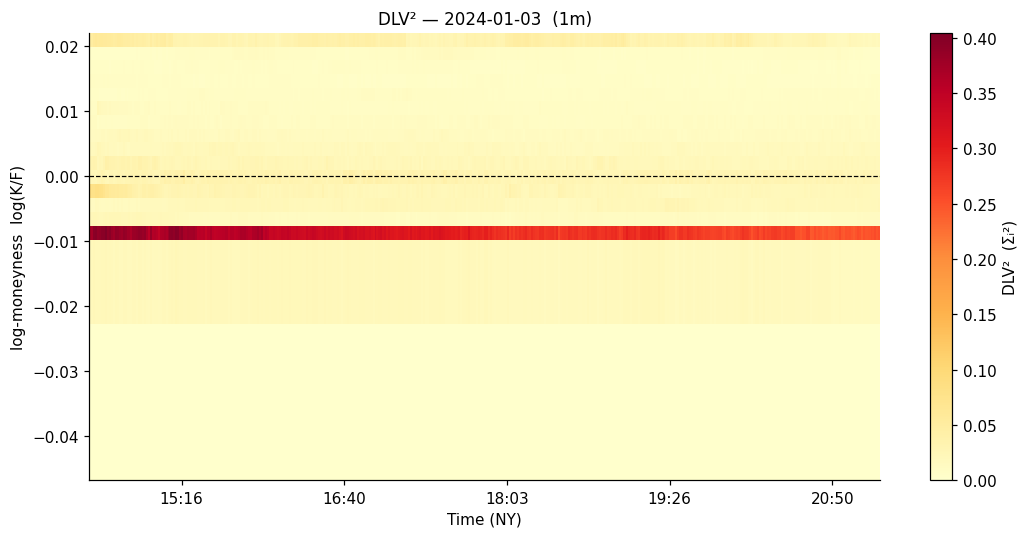

In [11]:
# ── DLV² heatmap ─────────────────────────────────────────────────────────

import datetime as _dt

from matplotlib.ticker import FuncFormatter

fmt = FuncFormatter(lambda x, _: _dt.datetime.fromtimestamp(x).strftime("%H:%M"))


def _ts_num(r):
    return r["ts"].timestamp() if hasattr(r["ts"], "timestamp") else float(r["ts"]) / 1e9


fig, ax = plt.subplots(1, 1, figsize=(10, 5))

if not good:
    ax.set_title("DLV² — no data", fontsize=11)
else:
    n = len(good)
    mat = np.full((len(interior_lk), n), np.nan)
    ts_nums = np.empty(n)
    for j, r in enumerate(good):
        mat[:, j] = r["dlvsqs"][0]
        ts_nums[j] = _ts_num(r)
    pcm = ax.pcolormesh(ts_nums, interior_lk, mat, cmap="YlOrRd", shading="nearest")
    fig.colorbar(pcm, ax=ax, label="DLV²  (Σᵢ²)")
    ax.xaxis.set_major_formatter(fmt)
    ax.set_xlabel("Time (NY)")
    ax.set_ylabel("log-moneyness  log(K/F)")
    ax.set_title(f"DLV² — {TRADE_DATE}  ({BATCH_FREQ})", fontsize=11)
    ax.axhline(0, color="black", lw=0.8, ls="--")

plt.tight_layout()
plt.show()

In [12]:
(mat >= 3.9).sum() / mat.shape[0] / mat.shape[1]

np.float64(0.0)

In [13]:
# ── DLV² heatmap (plotly) ────────────────────────────────────────────────

import datetime as _dt

import numpy as np
import plotly.graph_objects as go


def _ts_num(r):
    return r["ts"].timestamp() if hasattr(r["ts"], "timestamp") else float(r["ts"]) / 1e9


if not good:
    fig = go.Figure()
    fig.update_layout(title="DLV² — no data", width=1000, height=500)
else:
    n = len(good)
    mat = np.full((len(interior_lk), n), np.nan)
    ts = np.empty(n, dtype=object)
    for j, r in enumerate(good):
        mat[:, j] = r["dlvsqs"][0]
        ts[j] = _dt.datetime.fromtimestamp(_ts_num(r))  # local tz, mirrors your fmt

    fig = go.Figure(
        go.Heatmap(
            x=ts,
            y=interior_lk,
            z=mat,
            colorscale="YlOrRd",
            colorbar=dict(title="DLV²  (Σᵢ²)"),
            hovertemplate=("t=%{x|%H:%M}<br>log(K/F)=%{y:.4f}<br>DLV²=%{z:.4g}<extra></extra>"),
        )
    )
    fig.add_hline(y=0, line=dict(color="black", width=0.8, dash="dash"))
    fig.update_layout(
        title=f"DLV² — {TRADE_DATE}  ({BATCH_FREQ})",
        xaxis_title="Time (NY)",
        yaxis_title="log-moneyness  log(K/F)",
        width=1000,
        height=500,
    )
    fig.update_xaxes(tickformat="%H:%M")

fig.show()

In [14]:
mat.mean()

np.float64(0.03315179461866042)

In [15]:
# ── Risk-neutral density q heatmap ───────────────────────────────────────
import datetime as _dt
from zoneinfo import ZoneInfo

import plotly.graph_objects as go

_ny = ZoneInfo("America/New_York")

if not good:
    fig = go.Figure()
    fig.update_layout(title="Density q — no data")
else:
    n = len(good)
    mat = np.full((len(anchor_lk), n), np.nan)
    ts_nums = np.empty(n)
    for j, r in enumerate(good):
        mat[:, j] = r["densities"][0]
        ts_nums[j] = _ts_num(r)

    x_dt = [_dt.datetime.fromtimestamp(t, tz=_ny) for t in ts_nums]
    log_mat = np.log(np.where(mat > 0, mat, np.nan))

    fig = go.Figure(
        go.Heatmap(
            x=x_dt,
            y=anchor_lk,
            z=log_mat,
            colorscale="YlOrRd",
            colorbar=dict(title="log(qᵢ)"),
        )
    )

    fig.add_hline(y=0, line=dict(color="black", width=1, dash="dash"))

    fig.update_layout(
        title=f"Density q (log scale) — {TRADE_DATE}  ({BATCH_FREQ})",
        xaxis=dict(title="Time (NY)", tickformat="%H:%M"),
        yaxis=dict(title="log-moneyness  log(K/F)"),
        width=900,
        height=450,
    )

fig

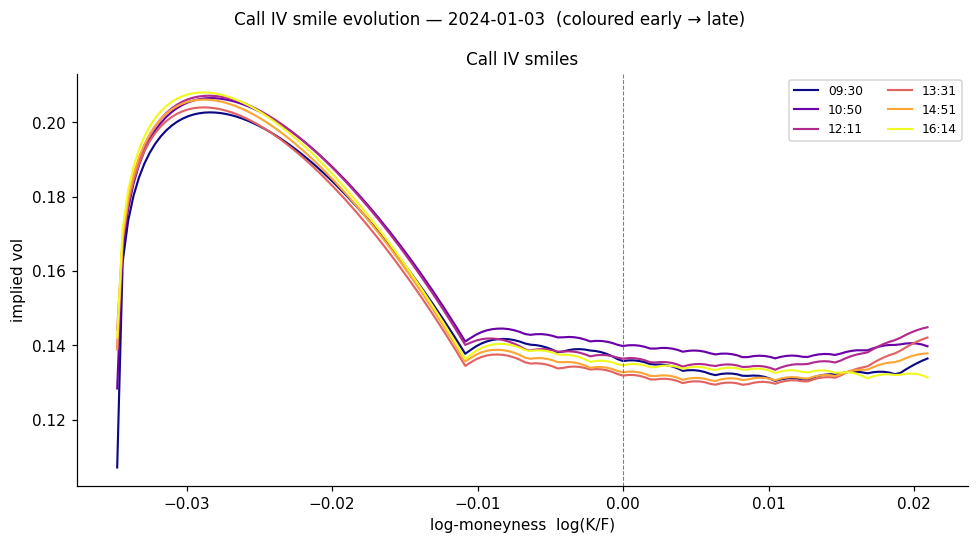

In [16]:
# ── Put/Call IV smile snapshots ───────────────────────────────────────────
# Dense grid clipped to the observed strike range to avoid showing the
# extrapolated region between the boundary pad anchor and the first observation.

obs_lk_lo = float(np.log(interior_pure[0]))  # first observed anchor (after lo_pad)
obs_lk_hi = float(np.log(interior_pure[-1]))  # last observed anchor (before hi_pad)

lk_dense = np.linspace(obs_lk_lo, obs_lk_hi, 150)
pk_dense = np.exp(lk_dense)
mask_dense = np.ones(len(pk_dense), dtype=bool)

viz_indices = np.linspace(0, len(good) - 1, min(N_VIZ, len(good)), dtype=int)
colors = [plt.cm.plasma(i / max(len(viz_indices) - 1, 1)) for i in range(len(viz_indices))]

iv_fn = _iv_from_norm_put if PUTS_ONLY else _iv_from_norm_call
ic = np.zeros(len(pk_dense), dtype=bool) if PUTS_ONLY else np.ones(len(pk_dense), dtype=bool)
opt_type = "Put" if PUTS_ONLY else "Call"

fig, ax = plt.subplots(1, 1, figsize=(9, 5))
ax.set_title(f"{opt_type} IV smiles", fontsize=11)

for i, color in zip(viz_indices, colors):
    r = good[int(i)]
    label = r["ts"].strftime("%H:%M") if hasattr(r["ts"], "strftime") else str(r["ts"])
    tte = np.full(len(pk_dense), r["T"])

    prices = grid_sanos.price(
        fwd_vols=None,
        densities=r["densities"],
        opt_strikes=pk_dense,
        opt_tte=tte,
        opt_is_call=ic,
        opt_mask=mask_dense,
    )
    ivs = np.array([iv_fn(float(p), float(k), r["T"]) for p, k in zip(prices, lk_dense)])
    mask = np.isfinite(ivs) & (ivs > 0)
    ax.plot(lk_dense[mask], ivs[mask], color=color, lw=1.4, label=label)

ax.set_xlabel("log-moneyness  log(K/F)")
ax.set_ylabel("implied vol")
ax.axvline(0, color="gray", lw=0.7, ls="--")
ax.legend(fontsize=8, ncol=2)

fig.suptitle(f"{opt_type} IV smile evolution — {TRADE_DATE}  (coloured early → late)", fontsize=11)
plt.tight_layout()
plt.show()

In [17]:
# the left hump is an artifact of IV inversion.

In [18]:
ivs.max() - ivs.min()

np.float64(0.0768779740153899)

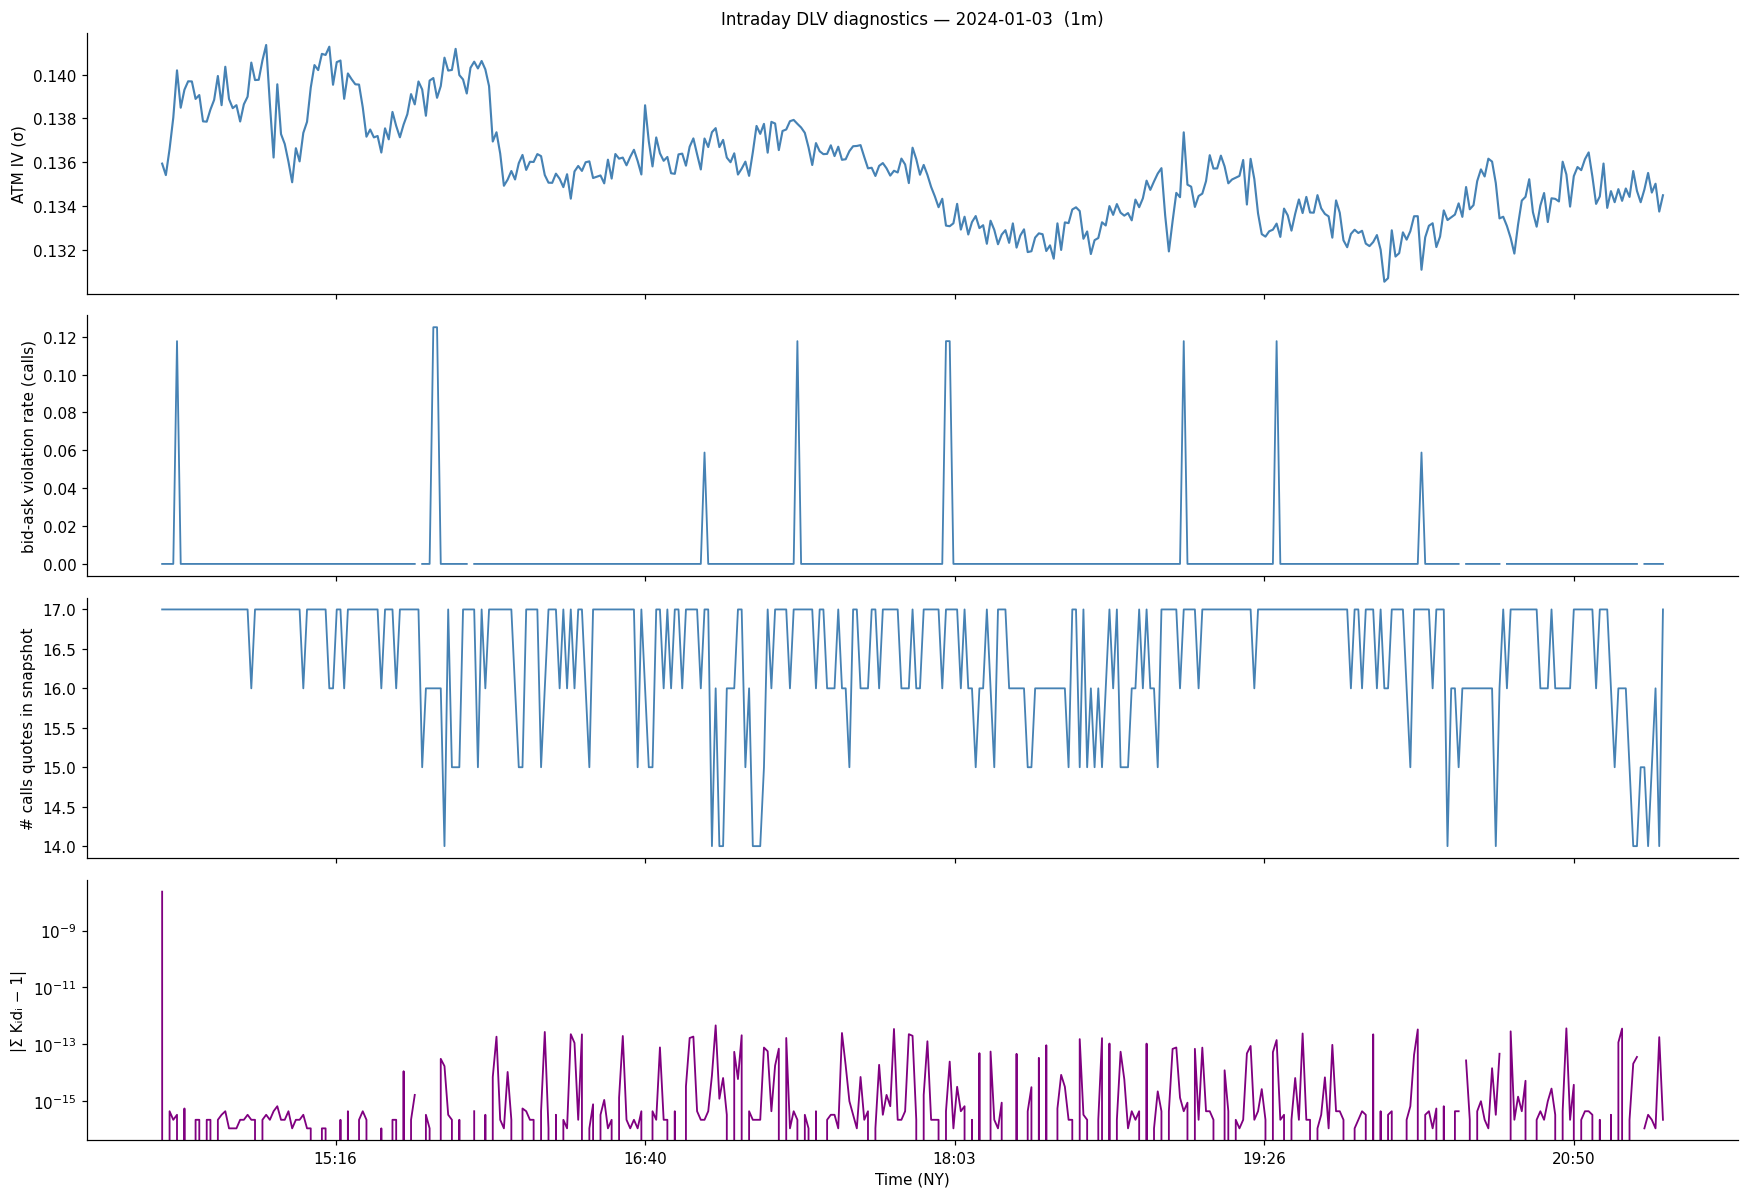

In [19]:
mart_res = []
for r in results:
    if r["densities"] is not None:
        d = r["densities"][0] if isinstance(r["densities"], np.ndarray) else r["densities"][0]
        mart_res.append(float(np.abs(anchor_pure @ d - 1.0)))
    else:
        mart_res.append(float("nan"))

# ── Fit quality metrics over time ─────────────────────────────────────────

ts_list, viol_obs, atm_iv_list, n_obs_list = [], [], [], []

for r in results:
    ts = r["ts"]
    snap_obs = (
        (snaps_puts if PUTS_ONLY else snaps_calls)
        .filter(pl.col("batch_ts") == ts)
        .sort("pure_strike")
    )

    ts_list.append(ts)
    atm_iv_list.append(r["atm_iv"])
    n_obs_list.append(r["n_puts"] if PUTS_ONLY else r["n_calls"])

    if r["densities"] is not None and not snap_obs.is_empty():
        pk_obs = snap_obs["pure_strike"].to_numpy().astype(float)
        bid_obs = snap_obs["bid_norm"].to_numpy().astype(float)
        ask_obs = snap_obs["ask_norm"].to_numpy().astype(float)
        is_call_arr = (
            np.zeros(len(pk_obs), dtype=bool) if PUTS_ONLY else np.ones(len(pk_obs), dtype=bool)
        )
        fit_obs = grid_sanos.price(
            None,
            r["densities"],
            opt_strikes=pk_obs,
            opt_tte=np.full(len(pk_obs), r["T"]),
            opt_is_call=is_call_arr,
            opt_mask=np.ones(len(pk_obs), dtype=bool),
        )
        viol_obs.append(float(((fit_obs < bid_obs) | (fit_obs > ask_obs)).mean()))
    else:
        viol_obs.append(float("nan"))

ts_nums = np.array([t.timestamp() if hasattr(t, "timestamp") else float(t) / 1e9 for t in ts_list])

fig, axes = plt.subplots(4, 1, figsize=(16, 11), sharex=True)

axes[0].plot(ts_nums, atm_iv_list, color="steelblue", lw=1.4)
axes[0].set_ylabel("ATM IV (σ)")
axes[0].set_title(f"Intraday DLV diagnostics — {TRADE_DATE}  ({BATCH_FREQ})", fontsize=11)

opt_label = "puts" if PUTS_ONLY else "calls"
axes[1].plot(ts_nums, viol_obs, color="steelblue", lw=1.2)
axes[1].set_ylabel(f"bid-ask violation rate ({opt_label})")

axes[2].plot(ts_nums, n_obs_list, color="steelblue", lw=1.2)
axes[2].set_ylabel(f"# {opt_label} quotes in snapshot")

axes[3].semilogy(ts_nums, mart_res, color="purple", lw=1.2)
axes[3].set_ylabel("|Σ Kᵢdᵢ − 1|")

for ax in axes:
    ax.xaxis.set_major_formatter(fmt)
axes[-1].set_xlabel("Time (NY)")
plt.tight_layout()
plt.show()

In [20]:
# ── SANOS vs call bid-ask: single snapshot ───────────────────────────────

import plotly.graph_objects as go

SNAP_IDX = 0  # which snapshot to display

r = good[SNAP_IDX]
label = r["ts"].strftime("%H:%M:%S") if hasattr(r["ts"], "strftime") else str(r["ts"])

# Dense grid for continuous SANOS curve
lk_curve = np.linspace(anchor_lk[0] + 0.01, anchor_lk[-1] - 0.01, 250)
pk_curve = np.exp(lk_curve)
tte_curve = np.full(len(pk_curve), r["T"])
mask_curve = np.ones(len(pk_curve), dtype=bool)

fig = go.Figure()

snap = (
    (snaps_puts if PUTS_ONLY else snaps_calls)
    .filter(pl.col("batch_ts") == r["ts"])
    .sort("pure_strike")
)

if not snap.is_empty() and r["densities"] is not None:
    pk_obs = snap["pure_strike"].to_numpy().astype(float)
    lk_obs = np.log(pk_obs)
    bid = snap["bid_norm"].to_numpy().astype(float)
    ask = snap["ask_norm"].to_numpy().astype(float)

    is_call_arr = (
        np.zeros(len(pk_obs), dtype=bool) if PUTS_ONLY else np.ones(len(pk_obs), dtype=bool)
    )
    fit_obs = grid_sanos.price(
        None,
        r["densities"],
        opt_strikes=pk_obs,
        opt_tte=np.full(len(pk_obs), r["T"]),
        opt_is_call=is_call_arr,
        opt_mask=np.ones(len(pk_obs), dtype=bool),
    )
    inside = (fit_obs >= bid) & (fit_obs <= ask)
    viol_pct = f"{(~inside).mean():.0%}"

    fit_curve = grid_sanos.price(
        None,
        r["densities"],
        opt_strikes=pk_curve,
        opt_tte=tte_curve,
        opt_is_call=np.zeros(len(pk_curve), dtype=bool)
        if PUTS_ONLY
        else np.ones(len(pk_curve), dtype=bool),
        opt_mask=mask_curve,
    )

    fig.add_trace(
        go.Scatter(
            x=lk_obs,
            y=ask,
            mode="lines+markers",
            line=dict(color="rgba(100,100,100,0.6)", width=1, dash="dot"),
            marker=dict(color="rgba(100,100,100,0.6)", size=4),
            name="ask",
            hovertemplate="lk=%{x:.4f}<br>ask=%{y:.5f}<extra>ask</extra>",
        )
    )
    fig.add_trace(
        go.Scatter(
            x=lk_obs,
            y=bid,
            mode="lines+markers",
            line=dict(color="rgba(100,100,100,0.6)", width=1, dash="dot"),
            marker=dict(color="rgba(100,100,100,0.6)", size=4),
            fill="tonexty",
            fillcolor="rgba(150,150,150,0.18)",
            name="bid (spread shaded)",
            hovertemplate="lk=%{x:.4f}<br>bid=%{y:.5f}<extra>bid</extra>",
        )
    )
    fig.add_trace(
        go.Scatter(
            x=lk_curve,
            y=fit_curve,
            mode="lines",
            line=dict(color="steelblue", width=2.5),
            name="SANOS fit",
            hovertemplate="lk=%{x:.4f}<br>SANOS=%{y:.5f}<extra>SANOS</extra>",
        )
    )
    if (~inside).any():
        fig.add_trace(
            go.Scatter(
                x=lk_obs[~inside],
                y=fit_obs[~inside],
                mode="markers",
                marker=dict(color="crimson", size=8, symbol="x-thin", line=dict(width=2)),
                name=f"violation ({viol_pct})",
                hovertemplate="lk=%{x:.4f}<br>fit=%{y:.5f}<extra>violation</extra>",
            )
        )

    fig.add_vline(x=0.0, line=dict(color="black", width=0.8, dash="dot"))

fig.update_xaxes(title_text="log(K/F)")
fig.update_yaxes(title_text="normalised call price")
fig.update_layout(
    title=dict(
        text=f"SANOS vs call bid-ask  |  {label}  —  {TRADE_DATE}  ({BATCH_FREQ})",
        font=dict(size=13),
    ),
    width=850,
    height=500,
    legend=dict(orientation="h", yanchor="bottom", y=-0.20, x=0.5, xanchor="center"),
    template="simple_white",
)
fig.show()

Max density perturbation (5% quote jitter): 2.6149e-03  [threshold 1e-2]
PASS ✓


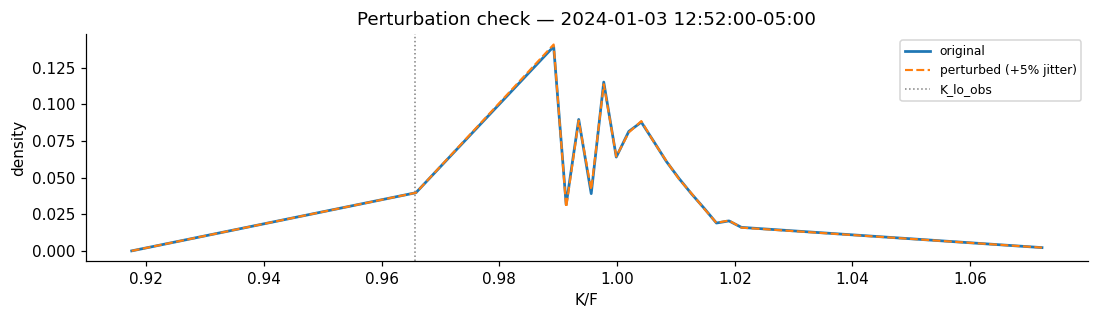

In [21]:
# ── Perturbation check: null space is resolved if the density is stable ─────
# Jitter quotes by ±5% of half-spread and confirm density doesn't jump.
# A large jump would mean the regularizer is too small to uniquify the null space.

r0 = good[len(good) // 2]
snap_data = snaps_puts if PUTS_ONLY else snaps_calls
snap = snap_data.filter(pl.col("batch_ts") == r0["ts"]).sort("pure_strike")
pk = snap["pure_strike"].to_numpy().astype(float)
bid0 = snap["bid_norm"].to_numpy().astype(float)
ask0 = snap["ask_norm"].to_numpy().astype(float)
tte0 = np.full(len(pk), r0["T"])
is_calls = np.zeros(len(pk), dtype=bool) if PUTS_ONLY else np.ones(len(pk), dtype=bool)

rng = np.random.default_rng(42)
half_sp = (ask0 - bid0) / 2.0
eps_j = rng.uniform(-0.05, 0.05, size=len(pk)) * half_sp
bid_j = np.maximum(1e-8, bid0 + eps_j)
ask_j = np.maximum(bid_j + 1e-6, ask0 + eps_j)

_, _, d_orig = fitter(
    fwd_vols=None,
    opt_strikes=pk,
    opt_bid=bid0,
    opt_ask=ask0,
    opt_tte=tte0,
    opt_is_calls=is_calls,
    return_only_dlvsqs=False,
)
_, _, d_pert = fitter(
    fwd_vols=None,
    opt_strikes=pk,
    opt_bid=bid_j,
    opt_ask=ask_j,
    opt_tte=tte0,
    opt_is_calls=is_calls,
    return_only_dlvsqs=False,
)

d0 = d_orig[0] if isinstance(d_orig, np.ndarray) else d_orig[0]
d1 = d_pert[0] if isinstance(d_pert, np.ndarray) else d_pert[0]
max_diff = float(np.max(np.abs(d0 - d1)))
print(f"Max density perturbation (5% quote jitter): {max_diff:.4e}  [threshold 1e-2]")
print(
    "PASS ✓" if max_diff < 0.01 else "WARNING: solution jumps — consider larger regularizer_weight"
)

# visualise
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(anchor_pure, d0, label="original", lw=1.8)
ax.plot(anchor_pure, d1, "--", label="perturbed (+5% jitter)", lw=1.4)
ax.axvline(r0.get("K_lo_obs", float("nan")), color="grey", lw=1, ls=":", label="K_lo_obs")
ax.set_xlabel("K/F")
ax.set_ylabel("density")
ax.set_title(f"Perturbation check — {r0['ts']}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [22]:
# ── Bid-ask arbitrage-free feasibility check ─────────────────────────────
# For each snapshot, check via LP whether there exists any price curve within
# the observed spreads that is arb-free (convex in K; monotone: calls decrease,
# puts increase with K — no call/put-spread or butterfly arb).

import datetime as _dt
from zoneinfo import ZoneInfo

import plotly.graph_objects as go
from scipy.optimize import linprog

_ny = ZoneInfo("America/New_York")


def bid_ask_arb_free(strikes, bids, asks, is_call=True):
    """Return (feasible: bool, prices: array | None).

    LP feasibility: does there exist C_i with b_i <= C_i <= a_i that is
    convex in strike and monotone (calls: decreasing; puts: increasing)?
    """
    K = np.asarray(strikes, dtype=float)
    n = len(K)
    if n < 2:
        return True, np.asarray(bids, dtype=float)

    A_ub, b_ub = [], []

    # Monotonicity
    for i in range(n - 1):
        row = np.zeros(n)
        if is_call:
            row[i + 1] = 1.0  # C_{i+1} - C_i <= 0  (calls decrease with K)
            row[i] = -1.0
        else:
            row[i] = 1.0  # P_i - P_{i+1} <= 0  (puts increase with K)
            row[i + 1] = -1.0
        A_ub.append(row)
        b_ub.append(0.0)

    # Convexity (butterfly >= 0) at each interior point, unequal spacing
    for i in range(1, n - 1):
        dK_l = K[i] - K[i - 1]
        dK_r = K[i + 1] - K[i]
        dK = K[i + 1] - K[i - 1]
        row = np.zeros(n)
        row[i - 1] = -dK_r / dK
        row[i] = 1.0
        row[i + 1] = -dK_l / dK
        A_ub.append(row)
        b_ub.append(0.0)

    res = linprog(
        np.zeros(n),
        A_ub=np.array(A_ub),
        b_ub=np.array(b_ub),
        bounds=list(zip(bids, asks)),
        method="highs",
    )
    feasible = res.status == 0
    return feasible, res.x if feasible else None


# ── Run for every snapshot in batch_ts_list ───────────────────────────────
snap_data = snaps_puts if PUTS_ONLY else snaps_calls
opt_label = "puts" if PUTS_ONLY else "calls"

arb_check = []
for batch_ts in tqdm(batch_ts_list, desc="Arb-free check"):
    snap = snap_data.filter(pl.col("batch_ts") == batch_ts).sort("pure_strike")
    if snap.is_empty():
        arb_check.append(dict(ts=batch_ts, feasible=None, n_strikes=0))
        continue

    K = snap["pure_strike"].to_numpy().astype(float)
    b = snap["bid_norm"].to_numpy().astype(float)
    a = snap["ask_norm"].to_numpy().astype(float)

    feasible, _ = bid_ask_arb_free(K, b, a, is_call=not PUTS_ONLY)
    arb_check.append(dict(ts=batch_ts, feasible=feasible, n_strikes=len(K)))

n_ok = sum(r["feasible"] is True for r in arb_check)
n_bad = sum(r["feasible"] is False for r in arb_check)
n_skip = sum(r["feasible"] is None for r in arb_check)
print(
    f"Snapshots: {len(arb_check)}  |  arb-free: {n_ok}  |  infeasible: {n_bad}  |  empty: {n_skip}"
)

if n_bad:
    print("\nInfeasible snapshots:")
    for r in arb_check:
        if r["feasible"] is False:
            label = r["ts"].strftime("%H:%M:%S") if hasattr(r["ts"], "strftime") else str(r["ts"])
            print(f"  {label}  ({r['n_strikes']} strikes)")

# ── Timeline bar chart ────────────────────────────────────────────────────
colors = []
for r in arb_check:
    if r["feasible"] is None:
        colors.append("lightgray")
    elif r["feasible"]:
        colors.append("seagreen")
    else:
        colors.append("crimson")

x_dt = [
    r["ts"].astimezone(_ny)
    if hasattr(r["ts"], "astimezone")
    else _dt.datetime.fromtimestamp(float(r["ts"]) / 1e9, tz=_ny)
    for r in arb_check
]

fig = go.Figure(
    go.Bar(
        x=x_dt,
        y=[r["n_strikes"] for r in arb_check],
        marker_color=colors,
        hovertemplate="%{x|%H:%M:%S}<br>strikes=%{y}<extra></extra>",
    )
)
fig.update_layout(
    title=(
        f"Bid-ask arb-free feasibility ({opt_label}) — {TRADE_DATE}  ({BATCH_FREQ})<br>"
        "<span style='font-size:12px'>green = feasible &nbsp; red = infeasible &nbsp; gray = empty</span>"
    ),
    xaxis=dict(title="Time (NY)", tickformat="%H:%M"),
    yaxis=dict(title=f"# {opt_label} strikes in snapshot"),
    width=900,
    height=380,
    template="simple_white",
    showlegend=False,
)
fig.show()

Snapshots: 405  |  arb-free: 405  |  infeasible: 0  |  empty: 0
